In [1]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/mragpavank/diabetes/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[cols] == 0).sum())
print()
print(df["Outcome"].value_counts())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Outcome
0    500
1    268
Name: count, dtype: int64


In [3]:
import numpy as np

df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())

print(df.isnull().sum())
df.describe()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": __import__("sklearn.ensemble", fromlist=["GradientBoostingClassifier"]).GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "CV Accuracy": round(cv, 3),
        "Test Accuracy": round(accuracy_score(y_test, pred), 3),
        "Test F1": round(f1_score(y_test, pred), 3),
    })

pd.DataFrame(results)

,Model,CV Accuracy,Test Accuracy,Test F1
0,Logistic Regression,0.782,0.708,0.545
1,Random Forest,0.769,0.740,0.600
2,Gradient Boosting,0.762,0.760,0.626


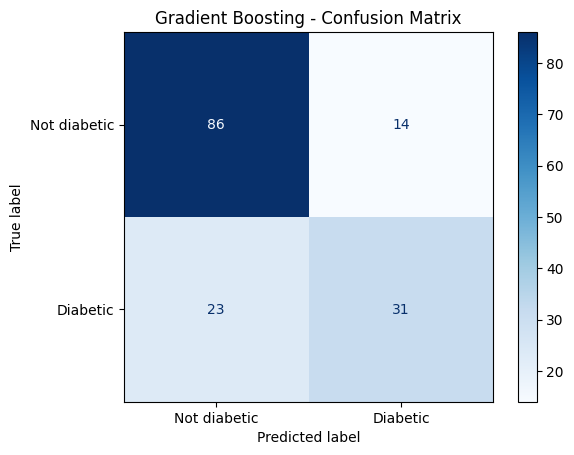

              precision    recall  f1-score   support

Not diabetic       0.79      0.86      0.82       100
    Diabetic       0.69      0.57      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.72       154
weighted avg       0.75      0.76      0.75       154



In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = models["Gradient Boosting"]
pred = best.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Not diabetic", "Diabetic"], cmap="Blues"
)
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

print(classification_report(y_test, pred, target_names=["Not diabetic", "Diabetic"]))

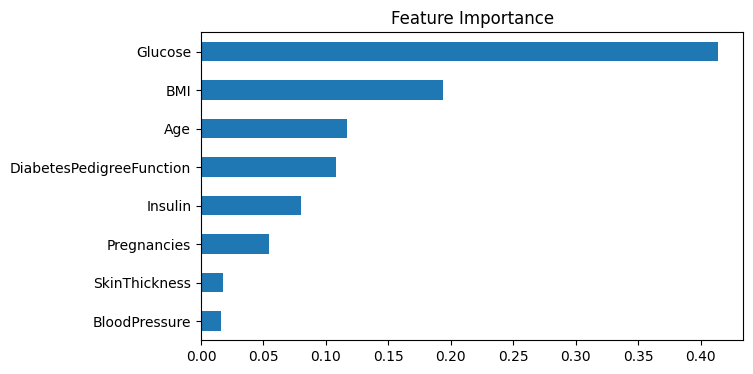

In [7]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Feature Importance")
plt.show()

In [8]:
import joblib

joblib.dump(best, "/kaggle/working/model.pkl")
print(list(X.columns))

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [9]:
import sklearn
print(sklearn.__version__)

1.6.1
